# Figure 3: Haplotype of origin of the EGFR amplicon relative to chr7 gain

This notebook reproduces the four panels of Figure 3. For four tumors it asks **which chr7 homolog the EGFR amplicon was built from**, and how that compares with the chr7 copy-number state of the rest of the chromosome.

The idea: blood heterozygous SNPs on chr7 are phased with WhatsHap, and the tumor reads are haplotagged (HP1 / HP2). At each phased SNP we count how many tumor reads support each haplotype. A haplotype that is amplified on the ecDNA, or gained on chr7, is over-represented in the tumor reads. Plotting the HP1 fraction along chr7 shows which homolog the amplicon came from.

| Panel | Tumor | Situation |
|---|---|---|
| upper left | GBM07 (`UM146`) | amplicon and chr7 gain on the **same** haplotype |
| upper right | GBM19 (`UM233`) | amplicon and chr7 gain on **opposite** haplotypes |
| lower left | GBM05 (`UM137`) | amplicon **without** chr7 gain |
| lower right | GBM16 (`UM220`) | chr7 gain with **LOH** |

Upstream steps (variant calling, phasing, haplotagging, per-SNP counting) are run on the raw data; their commands are listed in the appendix at the end.

## 0. Setup and inputs

Each tumor needs one table, `<sample>_haplotype_counts.tsv.gz`, produced by `haplotype_counts.py` (appendix). It has one row per blood heterozygous SNP on chr7 (columns: `chrom, pos, ref, alt, GT, PS, is_phased, DP_refalt, HP1_ref, HP2_ref, HP0_ref, HP1_alt, HP2_alt, HP0_alt, ...`), with read counts from the **tumor** haplotagged BAM.

`MANUAL_AMP_SPANS` are the EGFR amplicon boundaries for each tumor, taken from the CoRAL amplicon reconstructions and copy-number segments.

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

DATA_DIR = Path("/Users/isaacxu/Downloads/ecDNA/")      # folder holding <sample>_haplotype_counts.tsv.gz
OUT = Path("fig3_output")          # figures are written here
OUT.mkdir(exist_ok=True)

# EGFR amplicon boundaries on chr7 (hg38)
MANUAL_AMP_SPANS = {
    "UM137": (54_478_000, 56_025_000),   # GBM05
    "UM146": (54_415_000, 55_358_500),   # GBM07
    "UM220": (54_700_000, 55_200_000),   # GBM16
    "UM233": (54_775_000, 55_277_000),   # GBM19
}

# colours
COL_HP1 = "#4C78A8"            # blue
COL_HP2 = "#F2B342"            # yellow
COL_CONTEXT_DEPTH = "#D5D5D5"
COL_CONTEXT_POINT = "#B8B8B8"
COL_PS = "#8A8A8A"
COL_GUIDE = "#555555"
COL_GRID = "#BDBDBD"
COL_AMP = "#E8C547"

def count_file(sample):
    return DATA_DIR / f"{sample}_haplotype_counts.tsv.gz"

## 1. Load and clean the per-SNP haplotype counts

For each SNP we keep sites with `DP_refalt > 10` that are **phased heterozygous** (`0|1` or `1|0`).

Reads not carrying an `HP` tag (`HP0`) still contain information, because the allele they carry says which haplotype they came from. For a `0|1` SNP, HP1 carries the reference allele and HP2 the alternate allele, so `HP0_ref` is added to HP1 and `HP0_alt` to HP2 (reversed for `1|0`). The adjusted counts give

`HP_frac1_adj = HP1_total_adj / (HP1_total_adj + HP2_total_adj)`

A value of 0.5 means both homologs are equally represented. Values far from 0.5 mean one homolog is over-represented in the tumor reads.

In [2]:
def load_haplotype_counts(path, min_depth=10):
    snps = pd.read_csv(path, sep="\t")
    n_raw = len(snps)
    snps = snps[snps["DP_refalt"] > min_depth].reset_index(drop=True)
    n_after_depth = len(snps)

    m = snps["is_phased"].fillna(False) & snps["GT"].isin(["0|1", "1|0"])
    seg = snps.loc[m].copy()

    hp1 = seg["HP1_ref"] + seg["HP1_alt"]
    hp2 = seg["HP2_ref"] + seg["HP2_alt"]
    is_01 = seg["GT"] == "0|1"      # HP1 = ref, HP2 = alt
    is_10 = seg["GT"] == "1|0"      # HP1 = alt, HP2 = ref
    hp1.loc[is_01] += seg.loc[is_01, "HP0_ref"]
    hp2.loc[is_01] += seg.loc[is_01, "HP0_alt"]
    hp1.loc[is_10] += seg.loc[is_10, "HP0_alt"]
    hp2.loc[is_10] += seg.loc[is_10, "HP0_ref"]

    denom = hp1 + hp2
    snps.loc[m, "HP1_total_adj"] = hp1
    snps.loc[m, "HP2_total_adj"] = hp2
    snps.loc[m, "HP_frac1_adj"] = hp1 / denom
    snps.loc[m, "HP_maj_adj"] = np.maximum(hp1, hp2) / denom

    stats = {"n_raw": n_raw, "n_after_depth": n_after_depth, "n_phased_hets": int(m.sum())}
    return snps, stats

## 2. Which phase sets are informative?

WhatsHap phases SNPs into **phase sets**: blocks within which HP1/HP2 labels are consistent. Labels are arbitrary *between* phase sets, so HP1 in one block may be HP2 in the next. Haplotype fractions can therefore only be compared across positions that lie in the same phase set.

The **informative** phase sets are the ones that contain the left or right amplicon breakpoint, because they let us compare the amplicon with its flanking chr7 sequence on a common haplotype labelling. Only these are drawn in blue (HP1) and yellow (HP2). All other phase sets are shown in grey. Dashed black lines mark informative phase-set boundaries; dotted grey lines mark the others.

In [3]:
def first_existing_column(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def normalize_chromosome(c):
    c = str(c)
    return c if c.startswith("chr") else "chr" + c

def build_phase_set_table(df):
    """Canonical phase_set_id column + one row per phase set (start/end).

    Our count tables carry only the WhatsHap PS tag, so each phase set's display
    bounds are the first and last phased SNP observed in the plotted window.
    (Explicit start/end columns are used if a table has them.)"""
    df = df.copy()
    id_col = first_existing_column(df, ["phase_set_id", "ps", "PS", "phase_set", "PhaseSet"])
    st_col = first_existing_column(df, ["ps_start", "PS_START", "phase_set_start", "phase_start", "PhaseSetStart"])
    en_col = first_existing_column(df, ["ps_end", "PS_END", "phase_set_end", "phase_end", "PhaseSetEnd"])
    if id_col is None and st_col is None and en_col is None:
        raise ValueError("Could not identify phase-set columns in the haplotype-count table.")
    for c in [id_col, st_col, en_col]:
        if c is not None:
            df[c] = pd.to_numeric(df[c], errors="coerce")

    if st_col is not None and en_col is not None:
        parts = [df[st_col].astype("Int64").astype(str), df[en_col].astype("Int64").astype(str)]
        if id_col is not None:
            parts = [df[id_col].astype("Int64").astype(str)] + parts
        df["phase_set_id"] = parts[0]
        for p in parts[1:]:
            df["phase_set_id"] = df["phase_set_id"] + "_" + p
        phase_sets = (df.loc[df[st_col].notna() & df[en_col].notna(), ["phase_set_id", st_col, en_col]]
                      .drop_duplicates()
                      .rename(columns={st_col: "ps_start", en_col: "ps_end"}).copy())
    elif id_col is not None:
        df = df.loc[df[id_col].notna()].copy()
        df["phase_set_id"] = df[id_col].astype("Int64").astype(str)
        phase_sets = df.groupby("phase_set_id", as_index=False).agg(ps_start=("pos", "min"), ps_end=("pos", "max"))
    else:
        raise ValueError("Could not build phase sets from the available columns.")

    phase_sets["ps_start"] = pd.to_numeric(phase_sets["ps_start"], errors="coerce")
    phase_sets["ps_end"] = pd.to_numeric(phase_sets["ps_end"], errors="coerce")
    phase_sets = (phase_sets.dropna(subset=["phase_set_id", "ps_start", "ps_end"])
                  .sort_values(["ps_start", "ps_end"]).reset_index(drop=True))
    return df, phase_sets

def find_informative_phase_sets(phase_sets, amp_start, amp_end):
    """Phase set(s) containing the left and right amplicon breakpoints (may be the same set)."""
    ids, results = set(), {}
    for label, bp in {"left": amp_start, "right": amp_end}.items():
        m = phase_sets.loc[(phase_sets["ps_start"] <= bp) & (phase_sets["ps_end"] >= bp)].copy()
        results[label] = m
        ids.update(m["phase_set_id"].tolist())
    return ids, results

def get_phase_set_boundaries(phase_sets, xmin, xmax):
    b = np.unique(np.concatenate([phase_sets["ps_start"].to_numpy(float), phase_sets["ps_end"].to_numpy(float)]))
    return np.sort(b[(b >= xmin) & (b <= xmax)])

## 3. Plotting function

Each panel has two tracks:

* **Top**: depth at phased SNPs. In informative phase sets the depth is split into HP1 (blue, bottom) and HP2 (yellow, top).
* **Bottom**: HP1 fraction at each phased SNP. The dashed horizontal line marks 0.5 (balanced).

After each plot the function prints the informative phase sets and the median HP1 fraction in the left flank, inside the amplicon, and in the right flank.

In [4]:
def plot_haplotype_panel(path, xmin, xmax, sample, chrom="chr7", amp_start=None, amp_end=None,
                         min_depth=10, max_depth=250, figsize=(7.2, 4.6), title=None,
                         tick_interval=None, save=True, output_dir=OUT, output_prefix=None,
                         show_legend=True, show_context_fraction=True, show_amplicon_span=False,
                         emphasize_informative_boundaries=True):
    """Two-track phased-SNP panel. Only phase sets containing the left or right amplicon
    breakpoint are drawn in HP1/HP2 colours; every other phase set is grey context."""
    if amp_start is None or amp_end is None:
        amp_start, amp_end = MANUAL_AMP_SPANS[sample]

    snps, stats = load_haplotype_counts(path=path, min_depth=min_depth)
    d = snps.copy()
    if "chrom" in d.columns:
        d = d.loc[d["chrom"].astype(str).map(normalize_chromosome) == normalize_chromosome(chrom)].copy()
    d = d.loc[d["pos"].between(xmin, xmax, inclusive="both")].copy()
    d = d.dropna(subset=["pos", "DP_refalt", "HP_frac1_adj"]).sort_values("pos").reset_index(drop=True)
    if d.empty:
        raise ValueError(f"No eligible phased SNPs in {chrom}:{xmin:,}-{xmax:,}")

    d, phase_sets = build_phase_set_table(d)
    inf_ids, bp_results = find_informative_phase_sets(phase_sets, amp_start, amp_end)
    if not inf_ids:
        raise ValueError("Neither amplicon breakpoint fell inside an observed phase set.")
    inf_sets = phase_sets.loc[phase_sets["phase_set_id"].isin(inf_ids)].sort_values(["ps_start", "ps_end"]).reset_index(drop=True)
    d["is_informative"] = d["phase_set_id"].isin(inf_ids)

    x = d["pos"].to_numpy(float); depth = d["DP_refalt"].to_numpy(float); hp1 = d["HP_frac1_adj"].to_numpy(float)
    inf_mask = d["is_informative"].to_numpy(bool); ctx_mask = ~inf_mask
    boundaries = get_phase_set_boundaries(phase_sets, xmin, xmax)
    inf_bounds = set(inf_sets["ps_start"].astype(float)) | set(inf_sets["ps_end"].astype(float))

    fig, (ax_dep, ax_frac) = plt.subplots(2, 1, figsize=figsize, sharex=True,
                                          gridspec_kw={"height_ratios": [1.1, 2.0]})
    if show_amplicon_span:
        for ax in (ax_dep, ax_frac):
            ax.axvspan(amp_start, amp_end, color=COL_AMP, alpha=0.09, linewidth=0, zorder=0)

    # ---- top: phased SNP depth ----
    ax_dep.fill_between(x, 0, depth, color=COL_CONTEXT_DEPTH, alpha=0.90, linewidth=0, zorder=1)
    for pid in inf_ids:                       # separate fills so colour never bridges phase sets
        r = d.loc[d["phase_set_id"].eq(pid)].sort_values("pos")
        if r.empty:
            continue
        px = r["pos"].to_numpy(float); pdp = r["DP_refalt"].to_numpy(float); ph = r["HP_frac1_adj"].to_numpy(float)
        ax_dep.fill_between(px, 0, pdp * ph, color=COL_HP1, alpha=0.80, linewidth=0, zorder=2)
        ax_dep.fill_between(px, pdp * ph, pdp, color=COL_HP2, alpha=0.80, linewidth=0, zorder=2)
    ax_dep.plot(x, depth, color="black", linewidth=0.8, zorder=3)

    def draw_boundaries(ax):
        for b in boundaries:
            if emphasize_informative_boundaries and b in inf_bounds:
                ax.axvline(b, color="0.25", linestyle="--", linewidth=1.1, alpha=0.95, zorder=4)
            else:
                ax.axvline(b, color=COL_PS, linestyle=":", linewidth=0.65, alpha=0.65, zorder=1)
    draw_boundaries(ax_dep)

    ax_dep.set_ylim(0, max_depth)
    ax_dep.set_ylabel("Phased SNP\ndepth", fontsize=12)
    ax_dep.spines[["top", "right"]].set_visible(False)
    ax_dep.grid(axis="y", linewidth=0.3, alpha=0.35, color=COL_GRID)
    ax_dep.set_axisbelow(True)
    if show_legend:
        handles = [Patch(facecolor=COL_HP1, edgecolor="none", alpha=0.80, label="HP1"),
                   Patch(facecolor=COL_HP2, edgecolor="none", alpha=0.80, label="HP2"),
                   Patch(facecolor=COL_CONTEXT_DEPTH, edgecolor="none", alpha=0.90, label="Phase sets not used for assignment"),
                   Line2D([0], [0], color="0.25", linestyle="--", linewidth=1.1, label="Informative phase-set boundary")]
        if show_amplicon_span:
            handles.append(Patch(facecolor=COL_AMP, edgecolor="none", alpha=0.15, label="Amplicon"))
        ax_dep.legend(handles=handles, loc="upper left", frameon=True, facecolor="white",
                      edgecolor="#999999", framealpha=1.0, fontsize=7)

    # ---- bottom: HP1 fraction ----
    if show_context_fraction and ctx_mask.any():
        ax_frac.scatter(x[ctx_mask], hp1[ctx_mask], s=9, color=COL_CONTEXT_POINT, alpha=0.35, edgecolor="none", zorder=2)
    if inf_mask.any():
        ax_frac.scatter(x[inf_mask], hp1[inf_mask], s=11, color=COL_HP1, alpha=0.80,
                        edgecolor="black", linewidth=0.01, zorder=3)
    ax_frac.axhline(0.5, color=COL_GUIDE, linestyle="--", linewidth=1.3, alpha=0.90, zorder=2)
    draw_boundaries(ax_frac)
    ax_frac.set_ylim(-0.05, 1.05)
    ax_frac.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax_frac.set_ylabel("HP1 fraction", fontsize=12)
    ax_frac.set_xlabel(f"{chrom} position", fontsize=12)
    ax_frac.spines[["top", "right"]].set_visible(False)
    ax_frac.grid(axis="y", linewidth=0.3, alpha=0.35, color=COL_GRID)
    ax_frac.set_axisbelow(True)
    ax_frac.set_xlim(xmin, xmax)
    if tick_interval is None:
        span = xmax - xmin
        tick_interval = 0.25e6 if span <= 1.5e6 else 0.5e6 if span <= 3e6 else 1e6 if span <= 6e6 else 2e6
    ax_frac.xaxis.set_major_locator(mticker.MultipleLocator(tick_interval))
    ax_frac.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v / 1e6:.1f} Mb"))
    if title is not None:
        ax_dep.set_title(title, fontsize=13, fontweight="bold", pad=6)
    plt.tight_layout()

    if save:
        output_dir = Path(output_dir); output_dir.mkdir(parents=True, exist_ok=True)
        prefix = output_prefix or f"{sample}_phasing_panel"
        fig.savefig(output_dir / f"{prefix}.png", dpi=300, bbox_inches="tight")
        fig.savefig(output_dir / f"{prefix}.pdf", bbox_inches="tight")
    plt.show()

    # ---- printed summary ----
    print(f"Sample: {sample}")
    print(f"Raw rows: {stats['n_raw']:,}   after DP_refalt > {min_depth}: {stats['n_after_depth']:,}   "
          f"phased het SNPs: {stats['n_phased_hets']:,}   plotted: {len(d):,}")
    print(f"Phase-set boundaries in window: {len(boundaries):,}")
    print(f"Amplicon: {chrom}:{amp_start:,}-{amp_end:,}")
    print("Informative phase set(s):")
    print(inf_sets[["phase_set_id", "ps_start", "ps_end"]].to_string(index=False))
    for name, hits in bp_results.items():
        print(f"{name.capitalize()} breakpoint falls in phase set(s): {', '.join(hits['phase_set_id']) or 'none'}")

    left, amp, right = d["pos"] < amp_start, d["pos"].between(amp_start, amp_end), d["pos"] > amp_end
    med = {k: (float(d.loc[m, "HP_frac1_adj"].median()) if m.any() else np.nan)
           for k, m in [("left_flank", left), ("amplicon", amp), ("right_flank", right)]}
    for k, v in med.items():
        print(f"Median HP1 fraction, {k.replace('_', ' ')}: {v:.3f}")
    d.attrs["medians"] = med
    return d, fig

## 4. Panels

### 4A. Amplicon and chr7 gain on the same haplotype (GBM07)

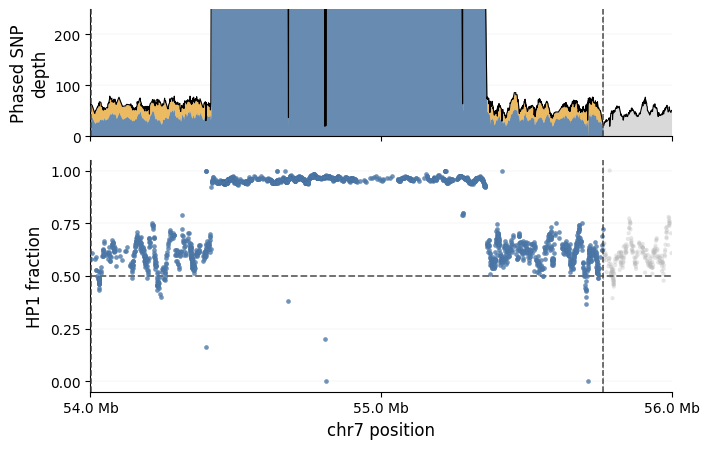

Sample: UM146
Raw rows: 9,351   after DP_refalt > 10: 9,344   phased het SNPs: 9,327   plotted: 2,443
Phase-set boundaries in window: 4
Amplicon: chr7:54,415,000-55,358,500
Informative phase set(s):
phase_set_id  ps_start   ps_end
    53724347  54000912 55762398
Left breakpoint falls in phase set(s): 53724347
Right breakpoint falls in phase set(s): 53724347
Median HP1 fraction, left flank: 0.600
Median HP1 fraction, amplicon: 0.957
Median HP1 fraction, right flank: 0.607


In [7]:
d146, fig146 = plot_haplotype_panel(
    path=count_file("UM146"), sample="UM146",
    xmin=54_000_000, xmax=56_000_000, tick_interval=1e6,
    show_legend=False, output_prefix="GBM07_phasing_panel")

### 4B. Amplicon and chr7 gain on opposite haplotypes (GBM19)

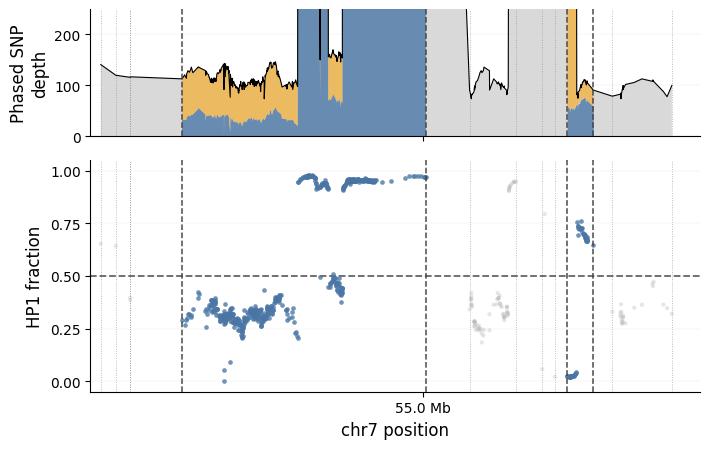

Sample: UM233
Raw rows: 8,484   after DP_refalt > 10: 8,451   phased het SNPs: 8,441   plotted: 739
Phase-set boundaries in window: 14
Amplicon: chr7:54,775,000-55,277,000
Informative phase set(s):
phase_set_id  ps_start   ps_end
    54565309  54565309 55005413
    55260332  55260332 55307406
Left breakpoint falls in phase set(s): 54565309
Right breakpoint falls in phase set(s): 55260332
Median HP1 fraction, left flank: 0.317
Median HP1 fraction, amplicon: 0.947
Median HP1 fraction, right flank: 0.670


In [8]:
d233, fig233 = plot_haplotype_panel(
    path=count_file("UM233"), sample="UM233",
    xmin=54_400_000, xmax=55_500_000, tick_interval=1e6,
    show_legend=False, output_prefix="GBM19_phasing_panel")

### 4C. Amplicon without chr7 gain (GBM05)

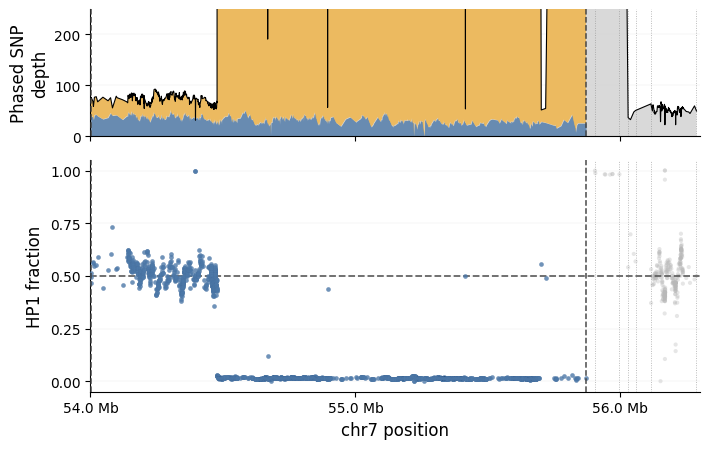

Sample: UM137
Raw rows: 9,540   after DP_refalt > 10: 9,526   phased het SNPs: 9,519   plotted: 2,290
Phase-set boundaries in window: 8
Amplicon: chr7:54,478,000-56,025,000
Informative phase set(s):
phase_set_id  ps_start   ps_end
    53720586  54000912 55869986
Left breakpoint falls in phase set(s): 53720586
Right breakpoint falls in phase set(s): none
Median HP1 fraction, left flank: 0.500
Median HP1 fraction, amplicon: 0.015
Median HP1 fraction, right flank: 0.500


In [9]:
d137, fig137 = plot_haplotype_panel(
    path=count_file("UM137"), sample="UM137",
    xmin=54_000_000, xmax=56_300_000, tick_interval=1e6,
    show_legend=False, output_prefix="GBM05_phasing_panel")

### 4D. chr7 gain with LOH (GBM16)

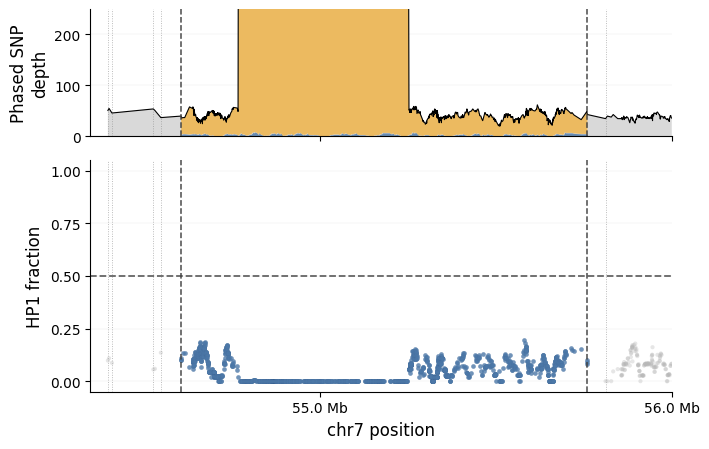

Sample: UM220
Raw rows: 9,101   after DP_refalt > 10: 9,091   phased het SNPs: 9,075   plotted: 1,562
Phase-set boundaries in window: 8
Amplicon: chr7:54,700,000-55,200,000
Informative phase set(s):
phase_set_id  ps_start   ps_end
    54607204  54607204 55759880
Left breakpoint falls in phase set(s): 54607204
Right breakpoint falls in phase set(s): 54607204
Median HP1 fraction, left flank: 0.114
Median HP1 fraction, amplicon: 0.002
Median HP1 fraction, right flank: 0.073


In [10]:
d220, fig220 = plot_haplotype_panel(
    path=count_file("UM220"), sample="UM220",
    xmin=54_350_000, xmax=56_000_000, tick_interval=1e6,
    show_legend=False, output_prefix="GBM16_phasing_panel")

### Legend

The legend is identical for all four panels, so it is drawn once here (as in the figure).

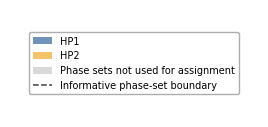

In [11]:
fig, ax = plt.subplots(figsize=(3.2, 1.4)); ax.axis("off")
ax.legend(handles=[
    Patch(facecolor=COL_HP1, alpha=0.80, label="HP1"),
    Patch(facecolor=COL_HP2, alpha=0.80, label="HP2"),
    Patch(facecolor=COL_CONTEXT_DEPTH, alpha=0.90, label="Phase sets not used for assignment"),
    Line2D([0], [0], color="0.25", linestyle="--", linewidth=1.1, label="Informative phase-set boundary")],
    loc="center", frameon=True, facecolor="white", edgecolor="#999999", fontsize=7)
#fig.savefig(OUT / "phasing_legend.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Summary of the four panels

Median HP1 fraction in the left flank, inside the amplicon and in the right flank. Within an informative phase set, a flank or amplicon median far from 0.5 indicates over-representation of one homolog; the direction (above or below 0.5) shows which one.

In [12]:
rows = []
for gbm, um, d in [("GBM07", "UM146", d146), ("GBM19", "UM233", d233),
                   ("GBM05", "UM137", d137), ("GBM16", "UM220", d220)]:
    med = d.attrs["medians"]
    rows.append({"tumor": gbm, "median HP1 frac, left flank": med["left_flank"],
                 "median HP1 frac, amplicon": med["amplicon"],
                 "median HP1 frac, right flank": med["right_flank"]})
summary = pd.DataFrame(rows).round(3)
#summary.to_csv(OUT / "fig3_summary.csv", index=False)
summary

,tumor,"median HP1 frac, left flank","median HP1 frac, amplicon","median HP1 frac, right flank"
0,GBM07,0.600,0.957,0.607
1,GBM19,0.317,0.947,0.670
2,GBM05,0.500,0.015,0.500
3,GBM16,0.114,0.002,0.073


## Appendix: how the count tables are produced

Run on the raw data, before this notebook, with `run_phasing_all.sh` (below). For each tumor it works on BAMs already subset to chr7:49-59 Mb (`<sample>_Blood_chr7_49_59mb.bam`, `<sample>_Tumor_chr7_49_59mb.bam`; HiFi reads aligned with minimap2 as in the other notebooks) and does:

1. **DeepVariant** (v1.6.1, PacBio model) on the blood BAM over chr7:49-59 Mb.
2. **bcftools**: keep PASS heterozygous SNPs.
3. **WhatsHap phase** the blood SNPs using the blood reads.
4. **WhatsHap haplotag** the tumor BAM with the blood phasing (adds `HP` and `PS` tags).
5. **`haplotype_counts.py`**: per-SNP ref/alt read counts split by `HP` tag in the tumor BAM. Its output (`<sample>_haplotype_counts.tsv`, gzipped) is the input of this notebook.

In [ ]:
%%writefile run_phasing_all.sh
#!/bin/bash
# Batch DeepVariant + phasing + haplotype counting for all tumor samples
# Usage: bash run_phasing_all.sh
# Skips samples that already have haplotype_counts.tsv

set -euo pipefail

REF="/home/ec2-user/ref/GRCh38_full_analysis_set_plus_decoy_hla.fa"
WHATSHAP=~/miniconda3/bin/whatshap
PYTHON=python3
HAPLOTYPE_SCRIPT="/home/ec2-user/haplotype_counts.py"
THREADS=16
REGION="chr7:49000000-59000000"

mkdir -p logs

# Sample manifest: one results/chr7 directory per sample
declare -A CHR7_DIRS=(
    ["UM29"]="/home/ec2-user/samples/UM29/results/chr7"
    ["UM116"]="/home/ec2-user/samples/UM116/results/chr7"
    ["UM124"]="/home/ec2-user/samples/UM124/results/chr7"
    ["UM141"]="/home/ec2-user/samples/UM141/results/chr7"
    ["UM159"]="/home/ec2-user/samples/UM159/results/chr7"
    ["UM209"]="/home/ec2-user/samples/UM209/results/chr7"
    ["UM215"]="/home/ec2-user/samples/UM215/results/chr7"
    ["UM220"]="/home/ec2-user/samples/UM220/results/chr7"
    ["UM221"]="/home/ec2-user/samples/UM221/results/chr7"
    ["UM229"]="/home/ec2-user/samples/UM229/results/chr7"
    ["UM233"]="/home/ec2-user/samples/UM233/results/chr7"
    ["UM244"]="/home/ec2-user/samples/UM244/results/chr7"
    ["UM245"]="/home/ec2-user/samples/UM245/results/chr7"
)

SAMPLE_ORDER=(UM29 UM116 UM124 UM141 UM159 UM209 UM215 UM220 UM221 UM229 UM233 UM244 UM245)

COMPLETED=0; SKIPPED=0; FAILED=0

for SAMPLE in "${SAMPLE_ORDER[@]}"; do

    DIR="${CHR7_DIRS[$SAMPLE]}"
    BLOOD_BAM="${DIR}/${SAMPLE}_Blood_chr7_49_59mb.bam"
    TUMOR_BAM="${DIR}/${SAMPLE}_Tumor_chr7_49_59mb.bam"
    COUNTS_TSV="${DIR}/${SAMPLE}_haplotype_counts.tsv"
    LOGFILE="logs/${SAMPLE}_phasing.log"

    # Skip if already done
    if [ -f "${COUNTS_TSV}" ]; then
        echo "[$(date)] SKIP (done): ${SAMPLE}"
        SKIPPED=$((SKIPPED+1)); continue
    fi

    # Check BAMs exist
    if [ ! -f "${BLOOD_BAM}" ] || [ ! -f "${TUMOR_BAM}" ]; then
        echo "[$(date)] SKIP (BAMs missing): ${SAMPLE}"
        echo "  Blood: $([ -f ${BLOOD_BAM} ] && echo OK || echo MISSING)"
        echo "  Tumor: $([ -f ${TUMOR_BAM} ] && echo OK || echo MISSING)"
        SKIPPED=$((SKIPPED+1)); continue
    fi

    echo ""
    echo "[$(date)] == ${SAMPLE} =="

    RAW_VCF="${DIR}/${SAMPLE}_Blood_chr7_49_59mb.vcf.gz"
    PASS_VCF="${DIR}/${SAMPLE}_Blood_chr7_PASS.vcf.gz"
    PHASED_VCF="${DIR}/${SAMPLE}_Blood_chr7_phased.vcf.gz"
    TAGGED_BAM="${DIR}/${SAMPLE}_Tumor_chr7_haplotagged.bam"

    {
    # Step 1: DeepVariant on the blood BAM
    if [ ! -f "${RAW_VCF}" ]; then
        echo "[$(date)] Step 1: DeepVariant on Blood..."
        docker run \
            -v "${DIR}:/input" \
            -v "/home/ec2-user/ref:/ref" \
            -v "${DIR}:/output" \
            google/deepvariant:1.6.1 \
            /opt/deepvariant/bin/run_deepvariant \
            --model_type PACBIO \
            --ref /ref/GRCh38_full_analysis_set_plus_decoy_hla.fa \
            --reads /input/$(basename ${BLOOD_BAM}) \
            --regions "${REGION}" \
            --output_vcf /output/$(basename ${RAW_VCF}) \
            --output_gvcf /output/${SAMPLE}_Blood_chr7_49_59mb.g.vcf.gz \
            --num_shards ${THREADS}
        echo "[$(date)] DeepVariant done"
    else
        echo "[$(date)] Step 1: DeepVariant VCF exists, skipping"
    fi

    # Step 2: keep PASS heterozygous SNPs
    echo "[$(date)] Step 2: Filtering PASS het SNPs..."
    bcftools view \
        --apply-filters PASS \
        --genotype het \
        --type snps \
        --output-type z \
        --output "${PASS_VCF}" \
        "${RAW_VCF}"
    bcftools index -t "${PASS_VCF}"
    N=$(bcftools view -H "${PASS_VCF}" | wc -l)
    echo "  PASS het SNPs: ${N}"

    # Step 3: phase with WhatsHap using the blood reads
    echo "[$(date)] Step 3: Phasing..."
    ${WHATSHAP} phase \
        --ignore-read-groups \
        --reference "${REF}" \
        --chromosome chr7 \
        --only-snvs \
        --output "${PHASED_VCF}" \
        "${PASS_VCF}" \
        "${BLOOD_BAM}"
    bcftools index -t "${PHASED_VCF}"

    # Step 4: haplotag the tumor BAM with the blood phasing
    echo "[$(date)] Step 4: Haplotagging tumor BAM..."
    ${WHATSHAP} haplotag \
        --ignore-read-groups \
        --reference "${REF}" \
        --output "${TAGGED_BAM}" \
        "${PHASED_VCF}" \
        "${TUMOR_BAM}"
    samtools index -@ ${THREADS} "${TAGGED_BAM}"

    # HP tag distribution
    echo "  HP tag distribution:"
    samtools view "${TAGGED_BAM}" \
        | grep -oP "HP:i:\K[0-9]" \
        | sort | uniq -c \
        | awk '{print "    HP"$2": "$1" reads"}'

    # Step 5: per-SNP haplotype counts
    echo "[$(date)] Step 5: Haplotype counting..."
    ${PYTHON} ${HAPLOTYPE_SCRIPT} \
        --vcf "${PHASED_VCF}" \
        --bam "${TAGGED_BAM}" \
        --out "${COUNTS_TSV}" \
        --sample "${SAMPLE}"

    echo "[$(date)] DONE: ${SAMPLE}"
    COMPLETED=$((COMPLETED+1))

    } > "${LOGFILE}" 2>&1

    if [ -f "${COUNTS_TSV}" ]; then
        echo "[$(date)] SUCCESS: ${SAMPLE} -> ${COUNTS_TSV}"
    else
        echo "[$(date)] FAILED: ${SAMPLE} - check ${LOGFILE}"
        FAILED=$((FAILED+1))
    fi

done

echo ""
echo "[$(date)] == Batch phasing complete =="
echo "  Completed: ${COMPLETED}"
echo "  Skipped:   ${SKIPPED}"
echo "  Failed:    ${FAILED}"

In [ ]:
%%writefile haplotype_counts.py
#!/usr/bin/env python3
"""
haplotype_counts.py
Extract per-variant haplotype read counts from a haplotagged BAM.
Uses the phased VCF for variant positions and the HP-tagged BAM for counts.

Usage:
    python haplotype_counts.py \
        --vcf  UM130_Blood_chr7_phased.vcf.gz \
        --bam  UM130_Tumor_chr7_haplotagged.bam \
        --out  UM130_haplotype_counts.tsv \
        --sample UM130
"""

import argparse
import pysam
import pandas as pd
import numpy as np
from collections import defaultdict

def parse_args():
    p = argparse.ArgumentParser()
    p.add_argument("--vcf",    required=True)
    p.add_argument("--bam",    required=True)
    p.add_argument("--out",    required=True)
    p.add_argument("--sample", default="SAMPLE")
    p.add_argument("--min_bq", type=int, default=20,
                   help="Min base quality [20]")
    p.add_argument("--min_mq", type=int, default=20,
                   help="Min mapping quality [20]")
    p.add_argument("--min_dp", type=int, default=5,
                   help="Min total depth to report [5]")
    return p.parse_args()

def load_phased_variants(vcf_path):
    """Load phased heterozygous SNPs from VCF."""
    variants = []
    vcf = pysam.VariantFile(vcf_path)
    for rec in vcf.fetch():
        # Only SNPs
        if len(rec.ref) != 1: continue
        alts = rec.alts
        if alts is None or len(alts) != 1: continue
        if len(alts[0]) != 1: continue

        # Get first sample genotype
        sample_data = list(rec.samples.values())[0]
        gt = sample_data.get("GT", (None, None))
        if None in gt: continue

        # Check if phased
        is_phased = sample_data.phased
        ps = sample_data.get("PS", None)

        # Only het variants (0|1 or 1|0)
        gt_set = set(gt)
        if gt_set != {0, 1}: continue

        variants.append({
            "chrom":     rec.chrom,
            "pos":       rec.pos,       # 1-based
            "ref":       rec.ref,
            "alt":       alts[0],
            "GT":        f"{gt[0]}|{gt[1]}" if is_phased else f"{gt[0]}/{gt[1]}",
            "PS":        ps,
            "is_phased": is_phased,
        })
    vcf.close()
    print(f"Loaded {len(variants)} phased het SNPs")
    return variants

def count_haplotype_bases(bam_path, variants, min_bq=20, min_mq=20):
    """
    For each variant position, count ref/alt bases split by HP tag.
    HP=1 → haplotype 1, HP=2 → haplotype 2, HP=0/missing → unphased
    """
    bam = pysam.AlignmentFile(bam_path, "rb")
    results = []

    for i, var in enumerate(variants):
        if (i+1) % 500 == 0:
            print(f"  Processing variant {i+1}/{len(variants)}...")

        chrom = var["chrom"]
        pos0  = var["pos"] - 1   # 0-based for pysam
        ref   = var["ref"].upper()
        alt   = var["alt"].upper()

        # Counts per HP tag
        counts = defaultdict(lambda: defaultdict(int))
        # counts[hp_tag][base] = count

        try:
            for col in bam.pileup(
                chrom, pos0, pos0+1,
                truncate=True,
                min_base_quality=min_bq,
                min_mapping_quality=min_mq,
                ignore_overlaps=True,
                flag_filter=3844,   # exclude unmapped, secondary, dup, supp
            ):
                if col.reference_pos != pos0:
                    continue
                for read in col.pileups:
                    if read.is_del or read.is_refskip:
                        continue
                    base = read.alignment.query_sequence[
                        read.query_position].upper()

                    # Get HP tag
                    try:
                        hp = read.alignment.get_tag("HP")
                    except KeyError:
                        hp = 0  # unphased reads

                    counts[hp][base] += 1

        except (ValueError, KeyError):
            pass

        # Aggregate
        def get(hp, base):
            return counts[hp].get(base, 0)

        hp1_ref = get(1, ref);  hp1_alt = get(1, alt)
        hp2_ref = get(2, ref);  hp2_alt = get(2, alt)
        hp0_ref = get(0, ref);  hp0_alt = get(0, alt)

        hp1_total = sum(counts[1].values())
        hp2_total = sum(counts[2].values())
        hp0_total = sum(counts[0].values())
        dp_refalt = hp1_ref+hp1_alt+hp2_ref+hp2_alt+hp0_ref+hp0_alt

        # Other bases (non ref/alt)
        other = sum(
            v for hp in counts
            for b, v in counts[hp].items()
            if b not in (ref, alt)
        )

        ref_count = hp1_ref + hp2_ref + hp0_ref
        alt_count = hp1_alt + hp2_alt + hp0_alt
        vaf = round(alt_count / dp_refalt, 4) if dp_refalt > 0 else np.nan

        hp1_frac = round(hp1_total / (hp1_total+hp2_total), 4) \
                   if (hp1_total+hp2_total) > 0 else np.nan

        results.append({
            **var,
            "DP_refalt":  dp_refalt,
            "ref_count":  ref_count,
            "alt_count":  alt_count,
            "VAF":        vaf,
            "HP1_total":  hp1_total,
            "HP2_total":  hp2_total,
            "HP0_total":  hp0_total,
            "HP1_frac":   hp1_frac,
            "HP1_ref":    hp1_ref,
            "HP2_ref":    hp2_ref,
            "HP0_ref":    hp0_ref,
            "HP1_alt":    hp1_alt,
            "HP2_alt":    hp2_alt,
            "HP0_alt":    hp0_alt,
            "other_bases":other,
        })

    bam.close()
    return results

def main():
    args = parse_args()
    print(f"Sample:  {args.sample}")
    print(f"VCF:     {args.vcf}")
    print(f"BAM:     {args.bam}")
    print(f"Output:  {args.out}")
    print()

    variants = load_phased_variants(args.vcf)
    if not variants:
        print("No phased variants found — check VCF")
        return

    print(f"Counting haplotype reads at {len(variants)} positions...")
    results = count_haplotype_bases(
        args.bam, variants,
        min_bq=args.min_bq,
        min_mq=args.min_mq
    )

    df = pd.DataFrame(results)

    # Filter by min depth
    df = df[df["DP_refalt"] >= args.min_dp].copy()

    # Column order matching your spec
    cols = [
        "chrom","pos","ref","alt","GT","PS","is_phased",
        "DP_refalt","ref_count","alt_count","VAF",
        "HP1_total","HP2_total","HP0_total","HP1_frac",
        "HP1_ref","HP2_ref","HP0_ref",
        "HP1_alt","HP2_alt","HP0_alt",
        "other_bases"
    ]
    df = df[cols]

    df.to_csv(args.out, sep="\t", index=False)
    print(f"\nSaved {len(df)} variants → {args.out}")

    # Quick summary
    phased = df[df["is_phased"]]
    print(f"\n── Summary ──────────────────────────────────────────────")
    print(f"  Total variants:   {len(df)}")
    print(f"  Phased:           {len(phased)}")
    print(f"  Median DP:        {df['DP_refalt'].median():.0f}")
    print(f"  Median VAF:       {df['VAF'].median():.3f}")
    if len(phased) > 0:
        print(f"  Median HP1 frac:  {phased['HP1_frac'].median():.3f}")
        print(f"  HP1 total reads:  {phased['HP1_total'].sum():,}")
        print(f"  HP2 total reads:  {phased['HP2_total'].sum():,}")
        print(f"  HP0 (unphased):   {phased['HP0_total'].sum():,}")

        # Haplotype of origin signal
        # If EGFR amp is on HP1: HP1_alt >> HP2_alt in amp region
        amp_region = phased[
            (phased["pos"] >= 54500000) &
            (phased["pos"] <= 55500000)
        ]
        if len(amp_region) > 0:
            hp1_alt_amp = amp_region["HP1_alt"].sum()
            hp2_alt_amp = amp_region["HP2_alt"].sum()
            print(f"\n  ── EGFR amp region (54.5-55.5Mb) ──")
            print(f"  HP1 alt reads: {hp1_alt_amp}")
            print(f"  HP2 alt reads: {hp2_alt_amp}")
            if hp1_alt_amp + hp2_alt_amp > 0:
                dominant = "HP1" if hp1_alt_amp > hp2_alt_amp else "HP2"
                ratio = max(hp1_alt_amp, hp2_alt_amp) / \
                        max(1, min(hp1_alt_amp, hp2_alt_amp))
                print(f"  → {dominant} appears to carry EGFR amp "
                      f"(ratio {ratio:.1f}x)")

if __name__ == "__main__":
    main()